# EECE568 - Assignment 2

### Mount on Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
%cd gdrive/My Drive/ubc/eece 568/EECE568_Assignment2/

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_768/690088547.py", line 1, in <cell line: 0>
    get_ipython().run_line_magic('cd', 'gdrive/My Drive/ubc/eece 568/EECE568_Assignment2/')
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 2418, in run_line_magic
    result = fn(*args, **kwargs)
  File "<decorator-gen-85>", line 2, in cd
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/magic.py", line 187, in <lambda>
    call = lambda f, *a, **k: f(*a, **k)
                              ~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/magics/osm.py", line 342, in cd
    oldcwd = os.getcwd()
OSError: [Errno 1

### Imports

In [ ]:
import time
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

# import standard PyTorch modules
import torch
import torch.nn as nn
import torch.optim as optim

# import torchvision module to handle image manipulation
import torchvision
import torchvision.transforms as transforms
print("Running on torch.__version__ = ", torch.__version__)

torch.backends.cudnn.deterministic = True

# utils
import os
from tqdm import tqdm
tqdm.pandas()
from collections import Counter

Running on torch.__version__ =  2.11.0+cu130


### Helper Functions

In [ ]:
# a function to move tensors from the CPU to the GPU and vice versa
def dict_to_device(orig, device):
    new = {}
    for k,v in orig.items():
        new[k] = v.to(device)
    return new

# a function to make gray-scale images the same shape as color images
def gray_to_color(x):
    return x.repeat(3, 1, 1)

# a function to plot a batch of images together
def plot_images(img, ax):
    img = torchvision.utils.make_grid(img)
    npimg = img.numpy()
    ax.imshow(np.transpose(npimg, (1, 2, 0)))

## Q1

### Dataset and Dataloader

In [ ]:
# Use standard MNIST dataset
class MyDataset(torchvision.datasets.MNIST):
    def __init__(self, *args, debug=False, **kwargs):
        super().__init__(*args, **kwargs)
        self.debug = debug

    def __getitem__(self, idx):
        data = super().__getitem__(idx)
        img = data[0]
        label = data[1]
        return {'image': img, 'label': label}

    def __len__(self):
        return super().__len__()

dataset = MyDataset(
    root = './',
    train = True,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(),
        gray_to_color,
    ]),
    debug=True,
)

loader = torch.utils.data.DataLoader(dataset, batch_size=128, num_workers=0)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.70MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 140kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.5MB/s]


### ToDo: train, validation, test split

The standard MNIST dataset does not provide a validation set. Use 20% of the training data as the validation set.

The standard MNIST dataset has a test set, and you can download it similar to downloading the train set, only by setting the train label to 'False'. Use the test set only for final the evaluation.

In [ ]:
# ToDo: load the test set
test_dataset = MyDataset(
    root='./',
    train=False,
    download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        gray_to_color,
    ]),
    debug=True,
)

In [ ]:
# ToDo: split the training data into train and validation, and define the dataloaders
train_loader = None
val_loader = None
test_loader = None

# Calculate split sizes
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

# Randomly split the training dataset
train_dataset, val_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Define DataLoaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

In [ ]:
# ToDo: print the size of train, validation, and test sets

print(f"Training set size:   {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size:       {len(test_dataset)}")

Training set size:   48000
Validation set size: 12000
Test set size:       10000


### Network

In [ ]:
# an example of using available models in PyTorch
class MyResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.resnet18 = torchvision.models.resnet18(num_classes=10)

    def forward(self, input_dict):
        pred_label = self.resnet18(input_dict['image'])
        return {'label': pred_label}

# a simple CNN model, implemented from the scratch
class MyNetwork(nn.Module):
    def __init__(self):
        super(MyNetwork, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=1)
        self.fc = nn.Linear(32*26*26, 10)

    def forward(self, input_dict):
        x = self.conv1(input_dict['image'])
        x = self.relu1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        pred_label = nn.functional.log_softmax(x, dim=1)

        return {'label': pred_label}

# You can choose either of the defined networks, or define your own neural net
network = MyNetwork().to('cuda')
print(network)

MyNetwork(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=21632, out_features=10, bias=True)
)


### Training

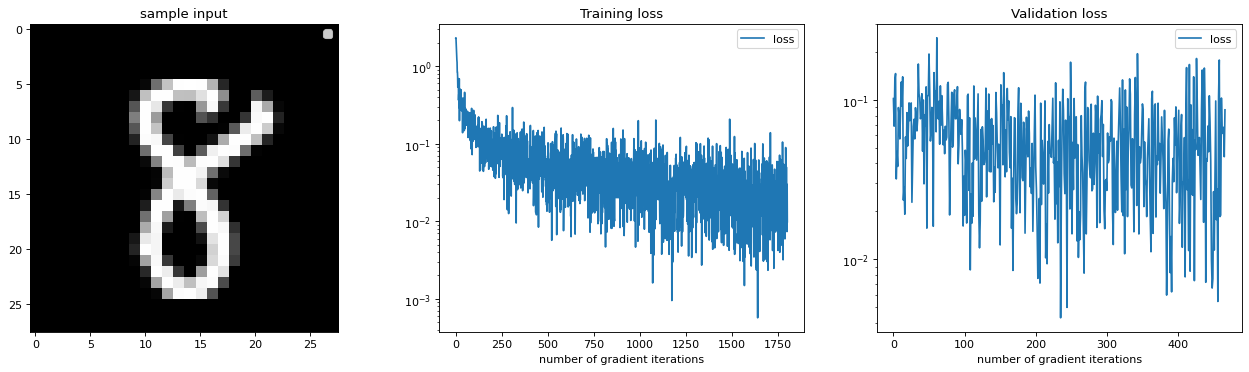

Validation epoch 4, iteration 90 of 94 (95 %), loss=0.08696664124727249


In [ ]:
# training loop
%matplotlib inline
from IPython import display

# prepare plotting
fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,3)

optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

num_epochs = 5
train_losses = []
val_losses = []

for e in range(num_epochs):
    train_iter = iter(train_loader)
    network.train()
    for i in range(len(train_loader)):
        batch_cpu = next(train_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss and backward the gradient
        loss = nn.CrossEntropyLoss()(pred['label'], batch_gpu['label'])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        if i%100==0:
            axes[0].cla()
            axes[1].cla()

            # plot some sample image inputs
            plot_images(batch_cpu['image'][0:1], ax=axes[0])
            axes[0].legend()
            axes[0].set_title('sample input')

            # plot the training error on a log plot
            axes[1].plot(train_losses, label='loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Training loss')
            axes[1].set_xlabel('number of gradient iterations')
            axes[1].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Training epoch {}, iteration {} of {} ({} %), loss={}".format(e, i, len(train_loader), 100*i//len(train_loader), train_losses[-1]))

    val_iter = iter(val_loader)
    network.eval()
    for i in range(len(val_loader)):
        batch_cpu = next(val_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss
        with torch.no_grad():
            loss = nn.CrossEntropyLoss()(pred['label'], batch_gpu['label'])
            val_losses.append(loss.item())

        if i%10==0:
            axes[2].cla()

            # plot the validation error on a log plot
            axes[2].plot(val_losses, label='loss')
            axes[2].set_yscale('log')
            axes[2].set_title('Validation loss')
            axes[2].set_xlabel('number of gradient iterations')
            axes[2].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Validation epoch {}, iteration {} of {} ({} %), loss={}".format(e, i, len(val_loader), 100*i//len(val_loader), val_losses[-1]))
plt.close('all')

### ToDo: Evaluation

Here we want to report the accuracy of the network's predictions. We have defined a function named 'get_accuracy' that returns the accuracy of the network on its input data.

Here, we assumed that the network returns class probabilities as output. If your network returns class indices, you need to change this evaluation function as well.

Print the accuracy of your network for the train, validation, and test sets.

In [ ]:
def get_accuracy(network, data_loader):
    network.eval()
    iterator = iter(data_loader)
    correct = 0
    total = 0
    for i in range(len(iterator)):
        batch_cpu = next(iterator)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)['label'].argmax(dim=1, keepdim=True)
        correct += pred.eq(batch_gpu['label'].view_as(pred)).sum().item()
        total += pred.shape[0]

    return correct / total

In [ ]:
# ToDo: report accuracy on train, validation, and test sets

train_accuracy = get_accuracy(network, train_loader)
val_accuracy = get_accuracy(network, val_loader)
test_accuracy = get_accuracy(network, test_loader)

print(f"Training Accuracy:   {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Test Accuracy:       {test_accuracy * 100:.2f}%")

Training Accuracy:   99.57%
Validation Accuracy: 98.64%
Test Accuracy:       98.75%


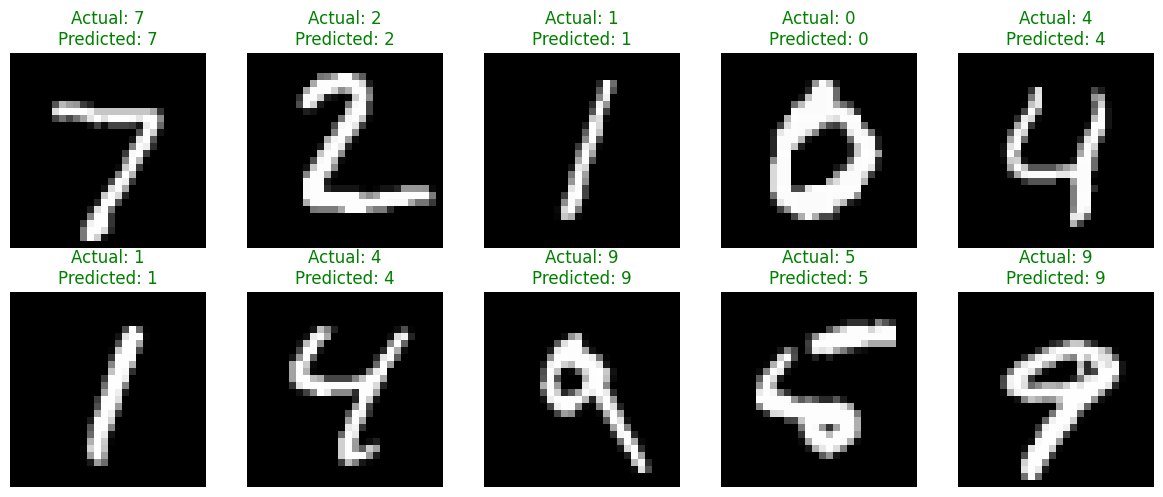

In [ ]:
# ToDo: Plot the input images and output of your network for a few samples in the test set
network.eval()

# Get a batch from the test set
batch_cpu = next(iter(test_loader))
batch_gpu = dict_to_device(batch_cpu, 'cuda')

# Get network predictions
with torch.no_grad():
    outputs = network(batch_gpu)['label']
    predictions = outputs.argmax(dim=1)

# Move images and labels to CPU for plotting
images = batch_cpu['image']
labels = batch_cpu['label']

# Plot the first 10 images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    # Convert image from [C, H, W] to [H, W, C]
    img = images[i].permute(1, 2, 0).numpy()

    # Display image
    ax.imshow(img, cmap='gray')

    # Get actual and predicted labels
    actual = labels[i].item()
    predicted = predictions[i].item()

    # Set title
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color='green' if actual == predicted else 'red'
    )

    ax.axis('off')

plt.tight_layout()
plt.show()

## Q2

### Dataset and Dataloader

In [ ]:
# Use standard MNIST dataset
class AnomalyDataset(torch.utils.data.Dataset):
    def __init__(self, data):
        self.data = data
        self.digits = {0:[], 1:[], 2:[], 3:[], 4:[]}
        for idx in range(len(self.data)):
            digit = self.data[idx][1]
            if digit in self.digits.keys():
                self.digits[digit].append(idx)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        norm, anomaly = random.sample(self.digits.keys(), k=2)
        anomaly_loc, = random.sample([0, 1, 2], k=1)
        norm1_idx, norm2_idx = random.sample(self.digits[norm], k=2)
        anomaly_idx, = random.sample(self.digits[anomaly], k=1)
        if anomaly_loc == 0:
            img0 = self.data[anomaly_idx][0]
            img1 = self.data[norm1_idx][0]
            img2 = self.data[norm2_idx][0]
        elif anomaly_loc == 1:
            img0 = self.data[norm1_idx][0]
            img1 = self.data[anomaly_idx][0]
            img2 = self.data[norm2_idx][0]
        elif anomaly_loc == 2:
            img0 = self.data[norm1_idx][0]
            img1 = self.data[norm2_idx][0]
            img2 = self.data[anomaly_idx][0]

        return {'img0': img0, 'img1': img1, 'img2': img2, 'index': anomaly_loc}

dataset = AnomalyDataset(torchvision.datasets.MNIST(
    root = './',
    train = True,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(),
        gray_to_color,
    ])
))

loader = torch.utils.data.DataLoader(dataset, batch_size=128, num_workers=0)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 44.1MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.18MB/s]


In [ ]:
print('Selected digits and their frequencies:')
for key, value in loader.dataset.digits.items():
    print(key, len(value))

Selected digits and their frequencies:
0 5923
1 6742
2 5958
3 6131
4 5842


### ToDo: train, validation, test split

Use 20% of the training data as the validation set.

The standard MNIST dataset has a test set, and you can download it similar to downloading the train set, only by setting the train label to 'False'. Use the test set only for final the evaluation.

In [ ]:
# ToDo: load the test set
test_dataset = AnomalyDataset(torchvision.datasets.MNIST(
    root='./',
    train=False,
    download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        gray_to_color,
    ])
))

In [ ]:
# ToDo: define the dataloaders
train_loader = None
val_loader = None
test_loader = None

train_size = int(0.8 * len(dataset.data))
val_size = len(dataset.data) - train_size
train_data, val_data = torch.utils.data.random_split(
    dataset.data,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)
train_dataset = AnomalyDataset(train_data)
val_dataset = AnomalyDataset(val_data)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=0)

class SampleableDict(dict): # NK needed to add this to make the next part work (set instead of dictionary)
    def keys(self):
        return list(super().keys())

for ds in (train_dataset, val_dataset, test_dataset):
    ds.digits = SampleableDict(ds.digits)


In [ ]:
# ToDo: print the size of train, validation, and test sets
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size: {len(test_dataset)}")

Training set size: 48000
Validation set size: 12000
Test set size: 10000


### ToDo: Network

Implement a neural network that takes three images as input and returns the index of the image with the different digit.

Your network should take a python dictionary as input and extract the input images from it. Your network should return a python dictionaly containing a key named 'index'.

In [ ]:
# ToDo: Implement your neural network from scratch
class MyNetwork(nn.Module):
    def __init__(self):
        super(MyNetwork, self).__init__()

        # ToDo: code here
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(3 * 32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 3),
        )

    def forward(self, input_dict):
        img0 = input_dict['img0']
        img1 = input_dict['img1']
        img2 = input_dict['img2']

        # ToDo: code here

        # Hint: use padding in conv layers to adjust the dimensions
        # Hint: max-pooling and ReLU layers can be useful
        # Hint: choose a suitable activation function for the last layer
        f0 = self.features(img0)
        f1 = self.features(img1)
        f2 = self.features(img2)
        pred_index = self.classifier(torch.cat((f0, f1, f2), dim=1))

        return {'index': pred_index}

network = MyNetwork().to('cuda')
print(network)

MyNetwork(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=4704, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=3, bias=True)
  )
)


### ToDo: Training

In [ ]:
# ToDo: define a suitable loss function
def my_loss_function(predicted_index, target_index):

  # code here
  loss = nn.functional.cross_entropy(predicted_index, target_index.long())

  return loss

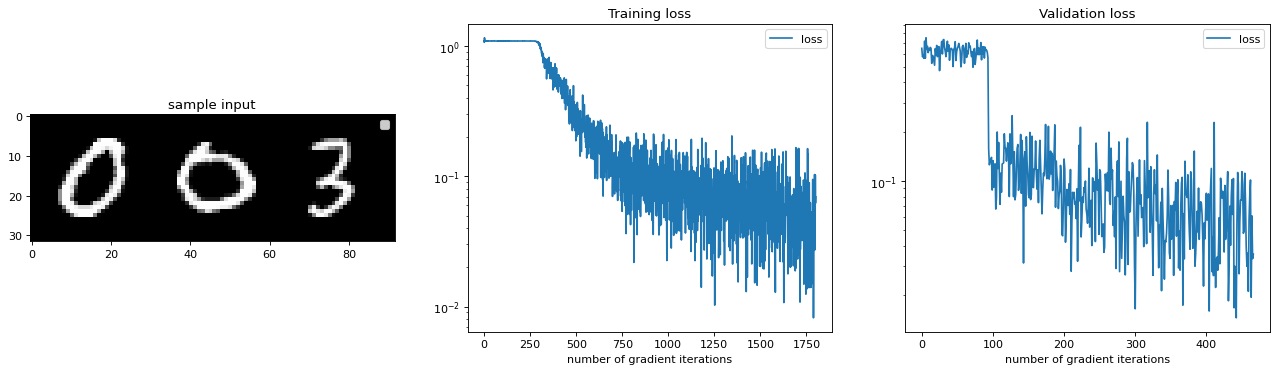

Validation epoch 4, iteration 90 of 94 (95 %), loss=0.0354042574763298


In [ ]:
# training loop
%matplotlib inline
from IPython import display

# prepare plotting
fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,3)

optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

num_epochs = 5
train_losses = []
val_losses = []

for e in range(num_epochs):
    train_iter = iter(train_loader)
    network.train()
    for i in range(len(train_loader)):
        batch_cpu = next(train_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss and backward the gradient
        loss = my_loss_function(pred['index'], batch_gpu['index'])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        if i%100==0:
            axes[0].cla()
            axes[1].cla()

            # plot some sample image inputs
            plot_images(torch.cat((batch_cpu['img0'][0:1], batch_cpu['img1'][0:1], batch_cpu['img2'][0:1]), 0), ax=axes[0])
            axes[0].legend()
            axes[0].set_title('sample input')

            # plot the training error on a log plot
            axes[1].plot(train_losses, label='loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Training loss')
            axes[1].set_xlabel('number of gradient iterations')
            axes[1].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Training epoch {}, iteration {} of {} ({} %), loss={}".format(e, i, len(train_loader), 100*i//len(train_loader), train_losses[-1]))

    val_iter = iter(val_loader)
    network.eval()
    for i in range(len(val_loader)):
        batch_cpu = next(val_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss
        with torch.no_grad():
            loss = my_loss_function(pred['index'], batch_gpu['index'])
            val_losses.append(loss.item())

        if i%10==0:
            axes[2].cla()

            # plot the validation error on a log plot
            axes[2].plot(val_losses, label='loss')
            axes[2].set_yscale('log')
            axes[2].set_title('Validation loss')
            axes[2].set_xlabel('number of gradient iterations')
            axes[2].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Validation epoch {}, iteration {} of {} ({} %), loss={}".format(e, i, len(val_loader), 100*i//len(val_loader), val_losses[-1]))
plt.close('all')

### ToDo: Evaluation

Here we want to report the accuracy of the network's predictions. We have defined a function named 'get_accuracy' that returns the accuracy of the network on its input data.

Here, we assumed that the network returns class probabilities as output. If your network returns class indices, you need to change this evaluation function as well.

Print the accuracy of your network for the train, validation, and test sets.

In [ ]:
def get_accuracy(network, data_loader):
    network.eval()
    iterator = iter(data_loader)
    correct = 0
    total = 0
    for i in range(len(iterator)):
        batch_cpu = next(iterator)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)['index'].argmax(dim=1, keepdim=True)
        correct += pred.eq(batch_gpu['index'].view_as(pred)).sum().item()
        total += pred.shape[0]

    return correct / total

In [ ]:
# ToDo: report accuracy on train, validation, and test sets
print(f"Training Accuracy: {get_accuracy(network, train_loader) * 100:.2f}%")
print(f"Validation Accuracy: {get_accuracy(network, val_loader) * 100:.2f}%")
print(f"Test Accuracy: {get_accuracy(network, test_loader) * 100:.2f}%")

Training Accuracy: 98.26%
Validation Accuracy: 98.08%
Test Accuracy: 98.68%


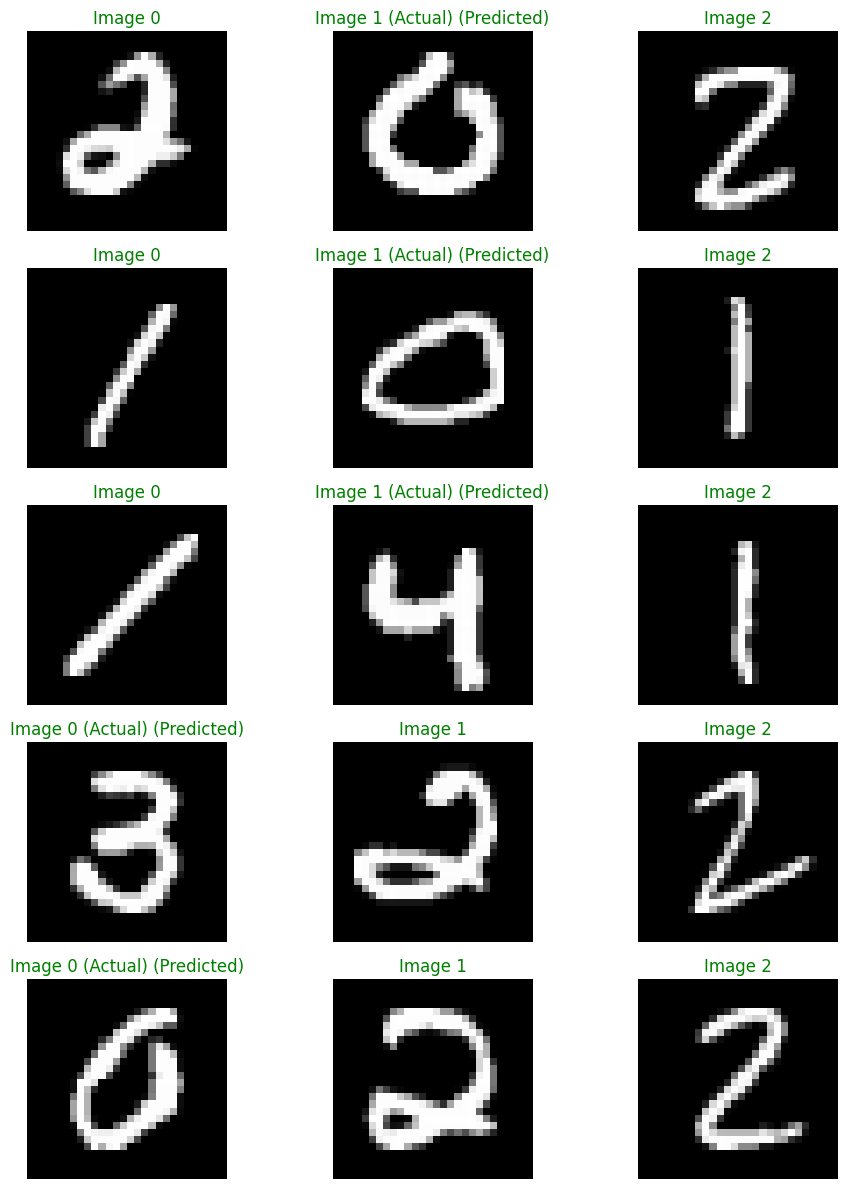

In [ ]:
# ToDo: Plot the input images and output of your network for a few samples in the test set
network.eval()
batch_cpu = next(iter(test_loader))
batch_gpu = dict_to_device(batch_cpu, 'cuda')
with torch.no_grad():
    predictions = network(batch_gpu)['index'].argmax(dim=1).cpu()

fig, axes = plt.subplots(5, 3, figsize=(10, 12))
for i in range(5):
    actual = batch_cpu['index'][i].item()
    predicted = predictions[i].item()
    for j in range(3):
        img = batch_cpu[f'img{j}'][i].permute(1, 2, 0).numpy()
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"Image {j}" + (" (Actual)" if j == actual else "") + (" (Predicted)" if j == predicted else ""), color='green' if actual == predicted else 'red')
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

## Q3

### Load and Tokenize Data

In [13]:
data = pd.read_csv('./imdb_processed.csv')
data.head()

,processed,label
0,One reviewer mentioned watching Oz episode hoo...,1
1,A wonderful little production . The filming te...,1
2,I thought wonderful way spend time hot summer ...,1
3,Basically family little boy Jake think zombie ...,0
4,Petter Mattei Love Time Money visually stunnin...,1


In [14]:
# obtain list of words
words = ' '.join(data.processed.values).split()

# check our list
words[30:40]

[',',
 'show',
 'faint',
 'hearted',
 'timid',
 '.',
 'This',
 'show',
 'pull',
 'punch']

In [15]:
# build vocabulary
counter = Counter(words)
vocab = sorted(counter, key=counter.get, reverse=True)
token2word = dict(enumerate(vocab, 1))
token2word[0] = '<PAD>'
word2token = {word: id for id, word in token2word.items()}

In [16]:
# tokenize reviews
reviews = data.processed.values
reviews_tokenized = [[word2token[word] for word in review.split()] for review in tqdm(reviews)]

# padding sequences
def pad_features(reviews, pad_id, seq_length):
    features = np.full((len(reviews), seq_length), pad_id, dtype=int)
    for i, row in enumerate(reviews):
        features[i, :len(row)] = np.array(row)[:seq_length]

    return features

features = pad_features(reviews_tokenized, pad_id=word2token['<PAD>'], seq_length=256)

print('number of reviews:', len(reviews_tokenized))
print('seq_length:', len(features[0]))

# print first-5 words of first 3 reviews
print('\n first-five words of the first-three reviews:')
print('===============')
features[:3, :5]

100%|██████████| 50000/50000 [00:01<00:00, 30650.82it/s]


number of reviews: 50000
seq_length: 256

 first-five words of the first-three reviews:


array([[ 191, 1083,  930,   81, 3724],
       [  47,  328,   59,  244,    1],
       [   3,   95,  328,   30, 1041]])

### Dataloader

In [17]:
# we use 70%, 15%, 15% for train, validation, and test sets
train_size = .7
val_size = .5
labels = data.label.to_numpy()

# make train set
split_id = int(len(features) * train_size)
train_x, remain_x = features[:split_id], features[split_id:]
train_y, remain_y = labels[:split_id], labels[split_id:]

# make val and test set
split_val_id = int(len(remain_x) * val_size)
val_x, test_x = remain_x[:split_val_id], remain_x[split_val_id:]
val_y, test_y = remain_y[:split_val_id], remain_y[split_val_id:]

# print out the shape
print('Train set: {}'.format(train_x.shape))
print('Validation set: {}'.format(val_x.shape))
print('Test set: {}'.format(test_x.shape))

Train set: (35000, 256)
Validation set: (7500, 256)
Test set: (7500, 256)


In [18]:
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, reviews, labels):
        self.data = torch.utils.data.TensorDataset(torch.from_numpy(reviews), torch.from_numpy(labels).float())

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        review = self.data[index][0]
        label = self.data[index][1]

        return {'review': review, 'label': label}


train_set = MyDataset(train_x, train_y)
val_set = MyDataset(val_x, val_y)
test_set = MyDataset(test_x, test_y)

train_loader = torch.utils.data.DataLoader(train_set, shuffle=True, batch_size=128)
val_loader = torch.utils.data.DataLoader(val_set, shuffle=True, batch_size=128)
test_loader = torch.utils.data.DataLoader(test_set, shuffle=True, batch_size=128)

### ToDo: Network

Implement a neural network based on Long short-term memory (LSTM) that takes a series of words (a review) as input and returns the label of the review indicating whether it is positive (1) or negative (0).

Your network should take a python dictionary as input and extract the input sentences from it. Your network should return a python dictionaly containing a key named 'label'.

In [19]:
# ToDo: Implement your neural network
class SentimentLSTM(nn.Module):
    def __init__(self):
        super(SentimentLSTM, self).__init__()

        # ToDo: code here

        # Hint: start with an embedding layer
        # Hint: using dropout might be useful
        # Hint: choose a suitable activation function for the last layer
        self.embedding = nn.Embedding(len(word2token), 128, padding_idx=word2token['<PAD>'])
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 1)


    def forward(self, input_dict):
        x = input_dict['review']

        # ToDo: code here
        lengths = (x != word2token['<PAD>']).sum(dim=1).clamp(min=1).cpu()
        embedded = self.embedding(x.long())
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        pred_label = torch.sigmoid(self.fc(self.dropout(hidden[-1]))).squeeze(-1)

        return {'label': pred_label}

network = SentimentLSTM().to('cuda')
print(network)

SentimentLSTM(
  (embedding): Embedding(121301, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


### ToDo: Training

In [20]:
# ToDo: define a suitable loss function
def my_loss_function(predicted_label, target_label):

  # code here
  loss = nn.functional.binary_cross_entropy(predicted_label, target_label)

  return loss

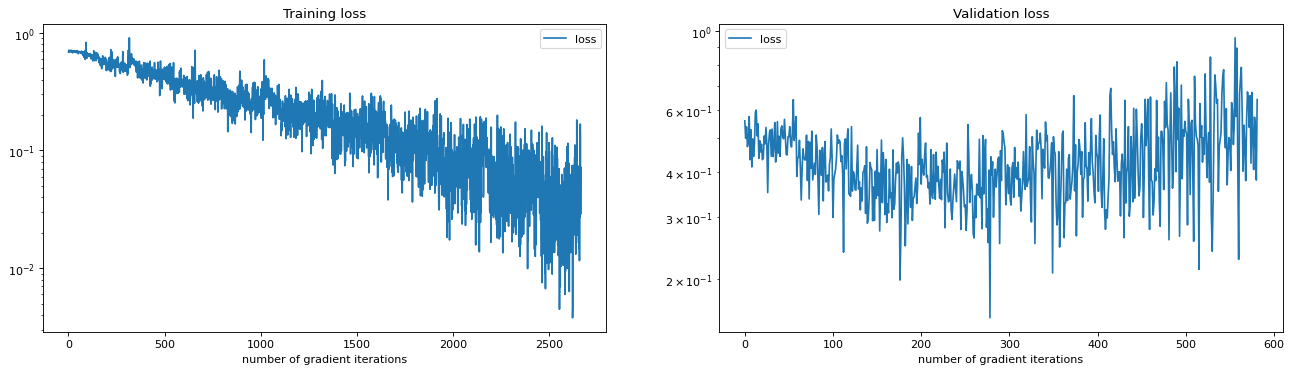

Validation epoch 9, iteration 50 of 59 (84 %), loss=0.6404712200164795


In [21]:
# training loop
%matplotlib inline
from IPython import display

# prepare plotting
fig = plt.figure(figsize=(20, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,2)

optimizer = torch.optim.Adam(network.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []

for e in range(num_epochs):
    train_iter = iter(train_loader)
    network.train()
    for i in range(len(train_loader)):
        batch_cpu = next(train_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss and backward the gradient
        loss = my_loss_function(pred['label'], batch_gpu['label'])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        if i%100==0:
            axes[0].cla()

            # plot the training error on a log plot
            axes[0].plot(train_losses, label='loss')
            axes[0].set_yscale('log')
            axes[0].set_title('Training loss')
            axes[0].set_xlabel('number of gradient iterations')
            axes[0].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Training epoch {}, iteration {} of {} ({} %), loss={}".format(e, i, len(train_loader), 100*i//len(train_loader), train_losses[-1]))

    val_iter = iter(val_loader)
    network.eval()
    for i in range(len(val_loader)):
        batch_cpu = next(val_iter)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)
        pred_cpu = dict_to_device(pred, 'cpu')

        # calculate the loss
        with torch.no_grad():
            loss = my_loss_function(pred['label'], batch_gpu['label'])
            val_losses.append(loss.item())

        if i%10==0:
            axes[1].cla()

            # plot the validation error on a log plot
            axes[1].plot(val_losses, label='loss')
            axes[1].set_yscale('log')
            axes[1].set_title('Validation loss')
            axes[1].set_xlabel('number of gradient iterations')
            axes[1].legend()

            # clear output window and diplay updated figure
            display.clear_output(wait=True)
            display.display(plt.gcf())
            print("Validation epoch {}, iteration {} of {} ({} %), loss={}".format(e, i, len(val_loader), 100*i//len(val_loader), val_losses[-1]))
plt.close('all')

### ToDo: Evaluation

Here we want to report the accuracy of the network's predictions. We have defined a function named 'get_accuracy' that returns the accuracy of the network on its input data.

Here, we assumed that the network returns class probabilities as output. If your network returns class indices, you might need to change this evaluation function as well.

Print the accuracy of your network for the train, validation, and test sets.

In [22]:
def get_accuracy(network, data_loader):
    network.eval()
    iterator = iter(data_loader)
    correct = 0
    total = 0
    for i in range(len(iterator)):
        batch_cpu = next(iterator)
        batch_gpu = dict_to_device(batch_cpu, 'cuda')
        pred = network(batch_gpu)['label']
        binary_pred = torch.where(pred < 0.5, 0, 1).squeeze(-1)
        correct += binary_pred.eq(batch_gpu['label']).sum().item()
        total += binary_pred.shape[0]

    return correct / total

In [23]:
# ToDo: report accuracy on train, validation, and test sets
print(f"Training accuracy:   {get_accuracy(network, train_loader) * 100:.2f}%")
print(f"Validation accuracy: {get_accuracy(network, val_loader) * 100:.2f}%")
print(f"Test accuracy:       {get_accuracy(network, test_loader) * 100:.2f}%")

Training accuracy:   99.26%
Validation accuracy: 86.13%
Test accuracy:       86.36%


In [24]:
# ToDo: print the input review and output of your network for one positive
#       example and one negative example in the test set
network.eval()
with torch.no_grad():
    for target in (1, 0):
        idx = next(i for i, label in enumerate(test_y) if int(label) == target)
        review_tokens = test_set[idx]['review']
        review = ' '.join(token2word[int(t)] for t in review_tokens if int(t) != word2token['<PAD>'])
        model_input = {'review': review_tokens.unsqueeze(0).to('cuda')}
        probability = network(model_input)['label'].item()
        prediction = int(probability >= 0.5)

        print(f"{'Positive' if target == 1 else 'Negative'} test example:")
        print(f"Review: {review}")
        print(f"Actual label: {target}")
        print(f"Predicted label: {prediction} (P(positive) = {probability:.3f})\n")

Positive test example:
Review: really liked film . feature John Wayne first starring performance . even , tell Wayne real presence , although really mature icon known Stagecoach , year later . settler country heading new west colonize . Wayne character Breck Coleman join , personal reason . main actor stage actor never done film , make movie even amazing . managed create believable , distinctive character quite oddball mix . Cimarron would come year later , similar story , though like much movie . , The Big Trail strong .
Actual label: 1
Predicted label: 1 (P(positive) = 1.000)

Negative test example:
Review: Remember Rick Mercer funny ? Minutes great show Rick Mercer Made In Canada great show . Talking To Americans funny special . But like friend said Rick Mercer woke one day funny I think day Rick Mercer Report went air . What point show ? Rick Mercer read wacky fake headline , show picture bad shed people mail spends minute minute show going somewhere talking people hoping say somet